In [29]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

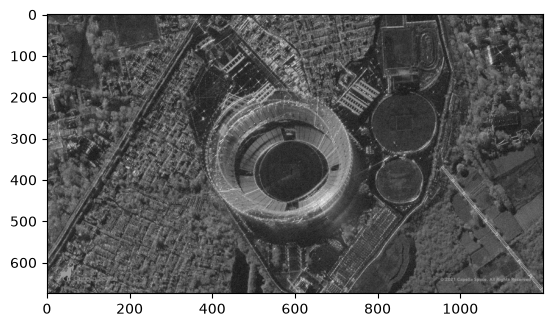

In [30]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap='gray')
plt.show()

Гауссов шум

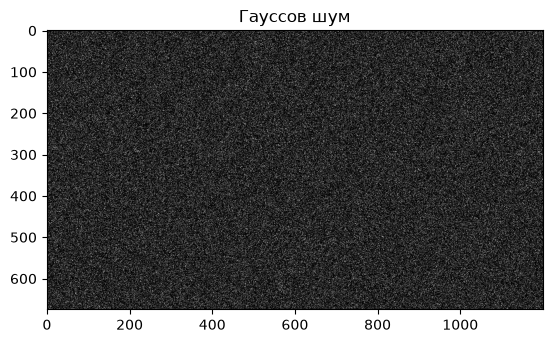

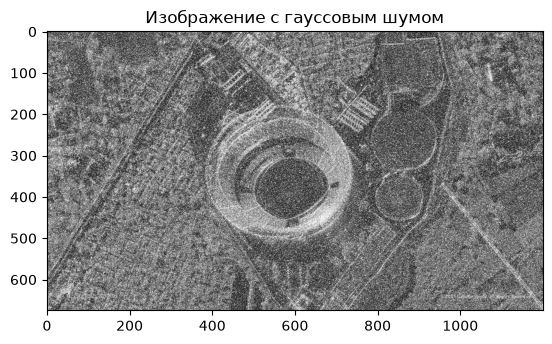

Гауссов шум: MSE = 4235.772919753086 , SSIM = 0.18731823597521827


In [31]:
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

plt.imshow(noise_gauss, cmap='gray')
plt.title('Гауссов шум')
plt.show()

image_noise_gauss = cv2.add(image_gray, noise_gauss)

plt.imshow(image_noise_gauss, cmap='gray')
plt.title('Изображение с гауссовым шумом')
plt.show()

mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim_gauss, _) = structural_similarity(image_gray, image_noise_gauss, full=True)
print("Гауссов шум: MSE =", mse_gauss, ", SSIM =", ssim_gauss)

Шум "соль и перец"

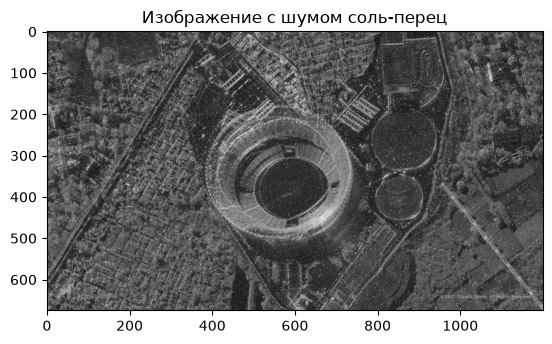

Соль-перец: MSE = 391.0713962962963 , SSIM = 0.7200574064739274


In [32]:
import copy

noise = np.random.randint(0, 101, size=(image_gray.shape[0], image_gray.shape[1]), dtype=int)
zeros_pixel = np.where(noise == 0) 
ones_pixel = np.where(noise == 100) 

image_sp = copy.deepcopy(image_gray)
image_sp[zeros_pixel] = 0 
image_sp[ones_pixel] = 255  

plt.imshow(image_sp, cmap='gray')
plt.title('Изображение с шумом соль-перец')
plt.show()

mse_sp = mean_squared_error(image_gray, image_sp)
(ssim_sp, _) = structural_similarity(image_gray, image_sp, full=True)
print("Соль-перец: MSE =", mse_sp, ", SSIM =", ssim_sp)

Фильтрация гауссова шума

Медиана: MSE = 1036.6538777777778 , SSIM = 0.4285539052509906


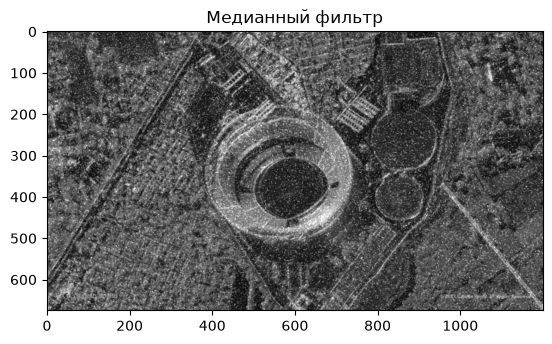

In [33]:
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)

mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, _) = structural_similarity(image_gray, image_gauss_median, full=True)
print("Медиана: MSE =", mse_gauss_median, ", SSIM =", ssim_gauss_median)

plt.imshow(image_gauss_median, cmap='gray')
plt.title('Медианный фильтр')
plt.show()

Остальные фильтры для гауссова шума

Гаусса: MSE = 1765.33, SSIM = 0.4866
Билатеральный: MSE = 1841.43, SSIM = 0.3143
Нелокальных средних: MSE = 4231.90, SSIM = 0.1877


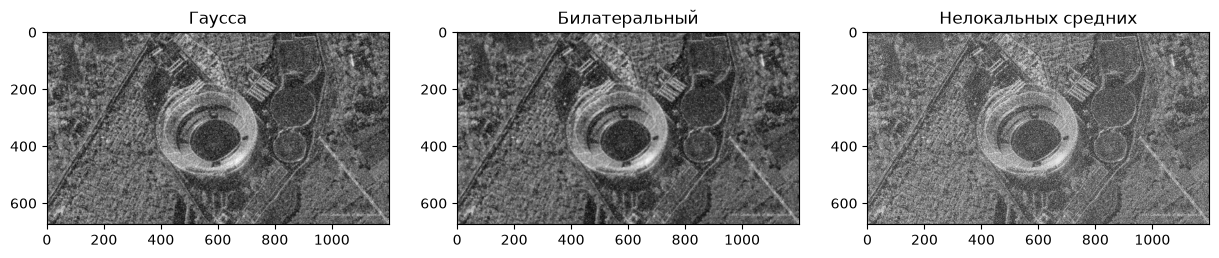

In [34]:
# Фильтр Гаусса
image_gauss_gauss = cv2.GaussianBlur(image_noise_gauss, (5, 5), 0)

# Билатеральный фильтр
image_gauss_bilat = cv2.bilateralFilter(image_noise_gauss, 9, 75, 75)

# Фильтр нелокальных средних
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss, h=20)

for name, img in [("Гаусса", image_gauss_gauss),
                  ("Билатеральный", image_gauss_bilat),
                  ("Нелокальных средних", image_gauss_nlm)]:
    m = mean_squared_error(image_gray, img)
    s, _ = structural_similarity(image_gray, img, full=True)
    print(f"{name}: MSE = {m:.2f}, SSIM = {s:.4f}")

plt.figure(figsize=(15, 10))
for i, (name, img) in enumerate([("Гаусса", image_gauss_gauss),
                                  ("Билатеральный", image_gauss_bilat),
                                  ("Нелокальных средних", image_gauss_nlm)]):
    plt.subplot(1, 3, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(name)
plt.show()

Фильтрация соли-перца

Медиана: MSE = 95.7364962962963 , SSIM = 0.8162952331193096


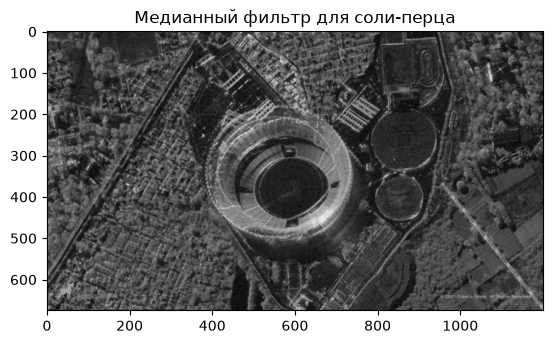

In [35]:
image_sp_median = cv2.medianBlur(image_sp, 3)

mse_sp_median = mean_squared_error(image_gray, image_sp_median)
(ssim_sp_median, _) = structural_similarity(image_gray, image_sp_median, full=True)
print("Медиана: MSE =", mse_sp_median, ", SSIM =", ssim_sp_median)

plt.imshow(image_sp_median, cmap='gray')
plt.title('Медианный фильтр для соли-перца')
plt.show()

Медианный фильтр (гауссов шум)
  k=3: MSE = 1036.65, SSIM = 0.4286
  k=5: MSE = 702.91, SSIM = 0.4686
  k=7: MSE = 678.96, SSIM = 0.4325
Фильтр Гаусса (гауссов шум)
  k=3: MSE = 1904.31, SSIM = 0.4408
  k=5: MSE = 1765.33, SSIM = 0.4866
  k=7: MSE = 1722.05, SSIM = 0.4930
Фильтр нелокальных средних (гауссов шум)
  h=20: MSE = 4231.90, SSIM = 0.1877
  h=50: MSE = 1761.45, SSIM = 0.3615
  h=100: MSE = 1890.95, SSIM = 0.2700


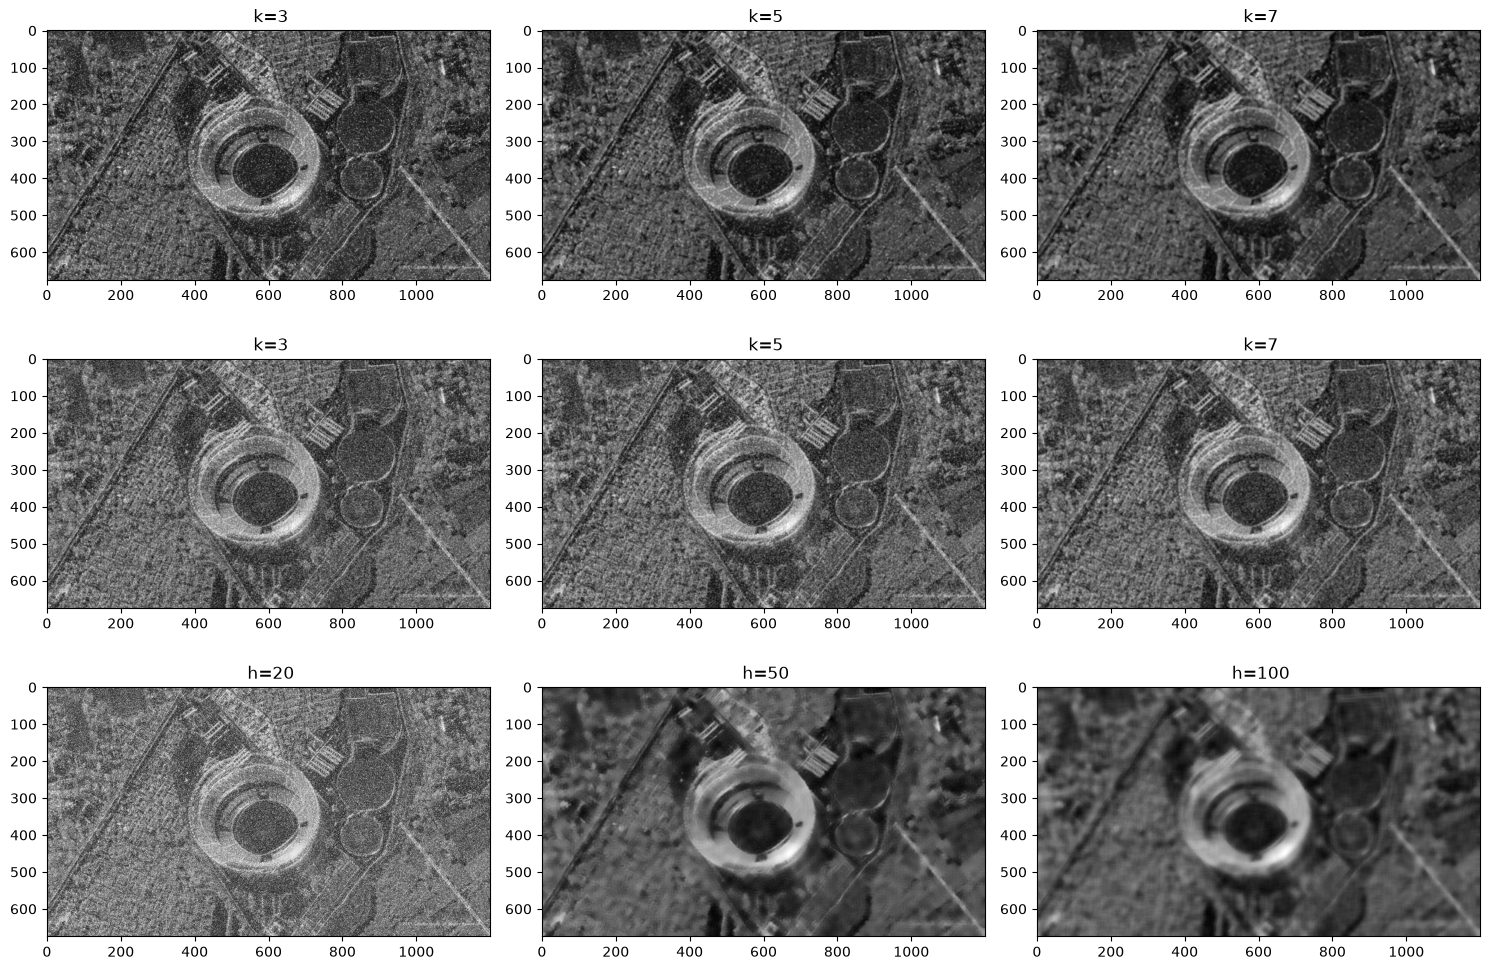

In [36]:
# Тест разных параметров фильтров
plt.figure(figsize=(15, 10))

print("Медианный фильтр (гауссов шум)")
for i, k in enumerate([3, 5, 7]):
    img = cv2.medianBlur(image_noise_gauss, k)
    m = mean_squared_error(image_gray, img)
    s = structural_similarity(image_gray, img)
    print(f"  k={k}: MSE = {m:.2f}, SSIM = {s:.4f}")
    plt.subplot(3, 3, i+1), plt.imshow(img, cmap='gray'), plt.title(f' k={k}')

print("Фильтр Гаусса (гауссов шум)")
for i, k in enumerate([3, 5, 7]):
    img = cv2.GaussianBlur(image_noise_gauss, (k, k), 0)
    m = mean_squared_error(image_gray, img)
    s = structural_similarity(image_gray, img)
    print(f"  k={k}: MSE = {m:.2f}, SSIM = {s:.4f}")
    plt.subplot(3, 3, i+4), plt.imshow(img, cmap='gray'), plt.title(f' k={k}')

print("Фильтр нелокальных средних (гауссов шум)")
for i, h in enumerate([20, 50, 100]):
    img = cv2.fastNlMeansDenoising(image_noise_gauss, h=h)
    m = mean_squared_error(image_gray, img)
    s = structural_similarity(image_gray, img)
    print(f"  h={h}: MSE = {m:.2f}, SSIM = {s:.4f}")
    plt.subplot(3, 3, i+7), plt.imshow(img, cmap='gray'), plt.title(f' h={h}')

plt.tight_layout()
plt.show()

Итоговое сравнение и вывод

In [37]:
print("Гауссов шум:")
print(f"  Медианный   : MSE = {mse_gauss_median:.2f}, SSIM = {ssim_gauss_median:.4f}")

m, s = mean_squared_error(image_gray, image_gauss_gauss), structural_similarity(image_gray, image_gauss_gauss)
print(f"  Гаусса : MSE = {m:.2f}, SSIM = {s:.4f}")

m, s = mean_squared_error(image_gray, image_gauss_bilat), structural_similarity(image_gray, image_gauss_bilat)
print(f"  Билатеральный: MSE = {m:.2f}, SSIM = {s:.4f}")

m, s = mean_squared_error(image_gray, image_gauss_nlm), structural_similarity(image_gray, image_gauss_nlm)
print(f"  Нелокальных средних  : MSE = {m:.2f}, SSIM = {s:.4f}")

print()
print("Соль-перец:")
print(f"  Медианый   : MSE = {mse_sp_median:.2f}, SSIM = {ssim_sp_median:.4f}")

Гауссов шум:
  Медианный   : MSE = 1036.65, SSIM = 0.4286
  Гаусса : MSE = 1765.33, SSIM = 0.4866
  Билатеральный: MSE = 1841.43, SSIM = 0.3143
  Нелокальных средних  : MSE = 4231.90, SSIM = 0.1877

Соль-перец:
  Медианый   : MSE = 95.74, SSIM = 0.8163


Вывод

Гауссов шум: лучший MSE у медианного фильтра (1035.58), лучший SSIM у фильтра Гаусса (0.4866).

Соль-перец: лучший результат у медианного фильтра (MSE = 95.87, SSIM = 0.8160).

Итог:против импульсного шума лучше всего работает медианный фильтр; против гауссова — медианный по MSE, гауссов по SSIM.